<a href="https://colab.research.google.com/github/minhphu12-oc/gg-colab/blob/sklearn-project-for-machine-learning/Project_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bước 1 : Đọc Dữ Liệu

1.1 gọi dataset và đọc 5 dòng đầu

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN, OPTICS
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [10]:
df = pd.read_csv('Mall_Customers.csv')
df.head(5)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


1.2 đọc thông tin dữ liệu

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


1.3 xem dữ liệu có đủ không

In [12]:
df.isnull().sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


1.4 visualize dữ liệu

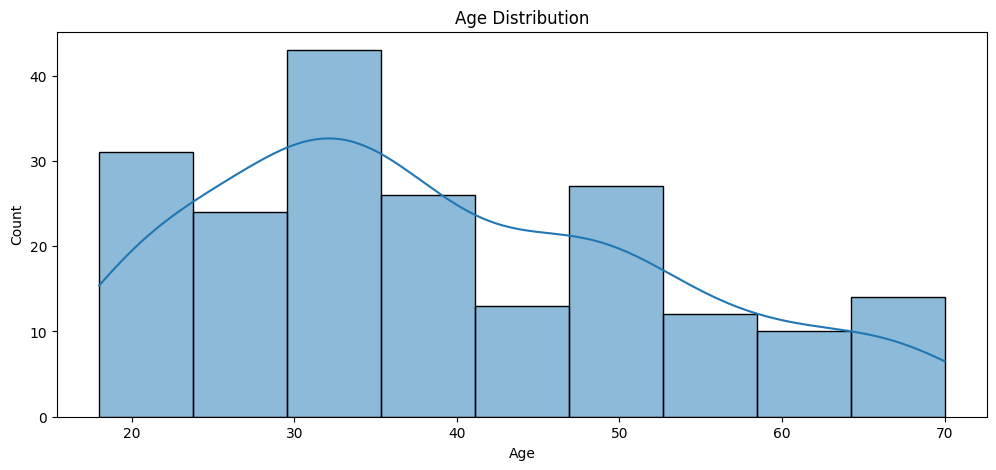

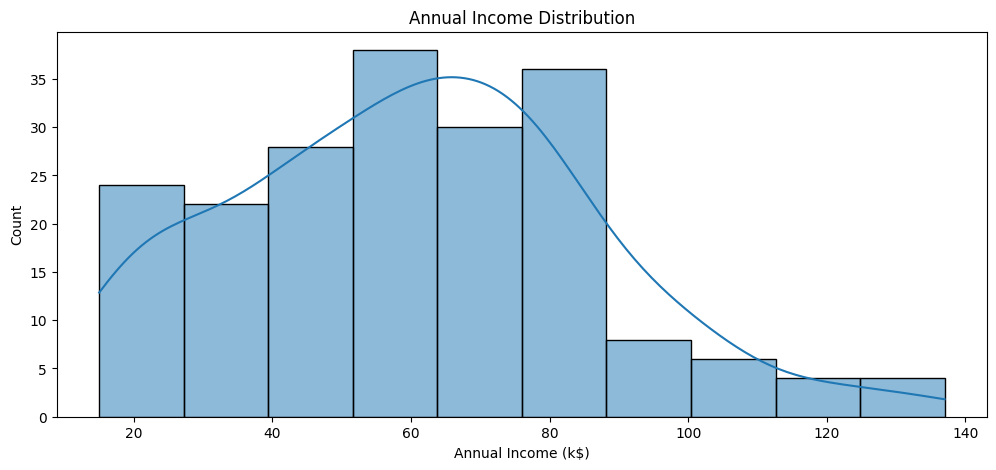

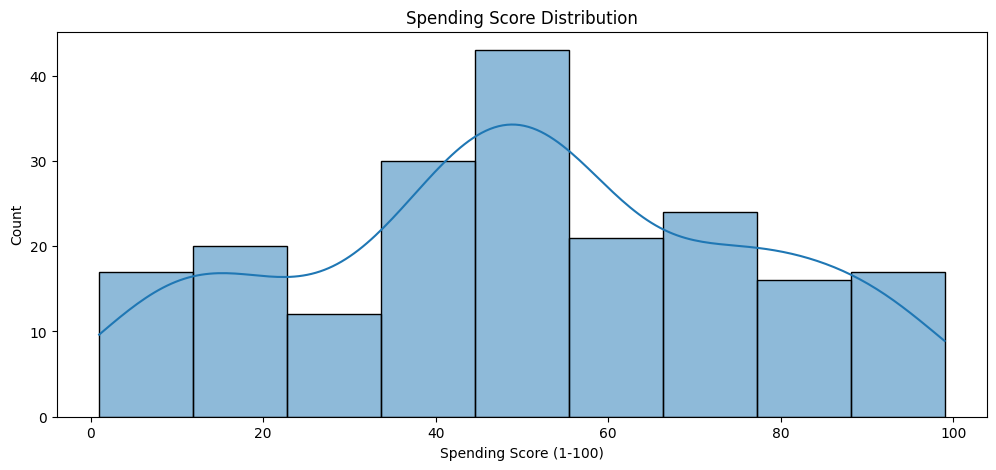

In [13]:
plt.figure(figsize=(12, 5))
sns.histplot(df['Age'], kde=True)
plt.title('Age Distribution')

plt.figure(figsize=(12, 5))

sns.histplot(df['Annual Income (k$)'], kde=True)
plt.title('Annual Income Distribution')

plt.figure(figsize=(12, 5))

sns.histplot(df['Spending Score (1-100)'], kde=True)
plt.title('Spending Score Distribution')
plt.show()

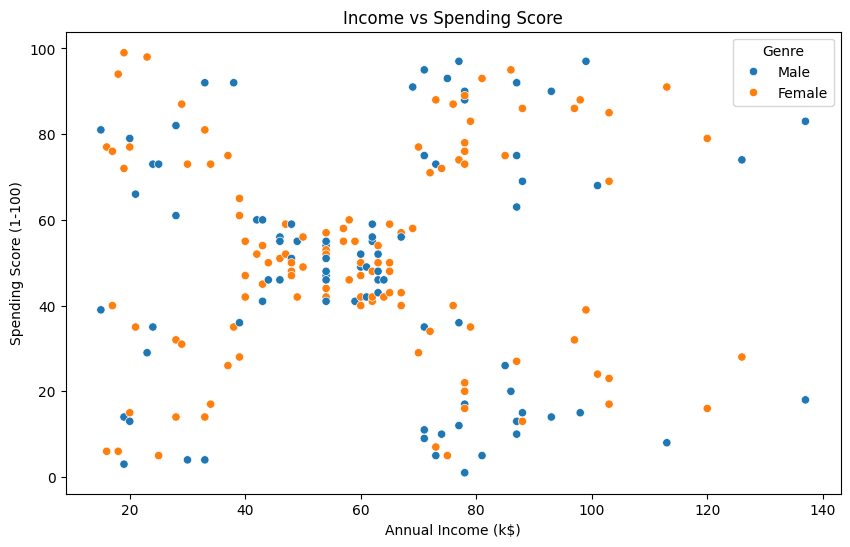

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue = 'Genre')

plt.title('Income vs Spending Score')
plt.show()

ta thấy được có 4 kiểu khách hàng khá đặc trưng:

1.   tiền ít nhưng mà chi tiêu rất nhiều
2.   tiền ít chi tiêu rất ít
3. tiền nhiều chi tiêu rất nhiều
4. tiền nhiều nhưng chi tiêu rất ít



# Bước 2: Tiền xử lí dữ liệu

mục tiêu là phân loại phân khúc khách hàng dựa vào tài chính chi tiêu nên chúng ta sẽ không đưa genre và customer id vào để tránh việc đo nhầm khoảng cách giữa male và female

In [26]:
feature = df[['Annual Income (k$)', 'Spending Score (1-100)']]
scaler = StandardScaler()
x = scaler.fit_transform(feature)
data_before = feature.copy()

2.1 Tại sao phải scaler

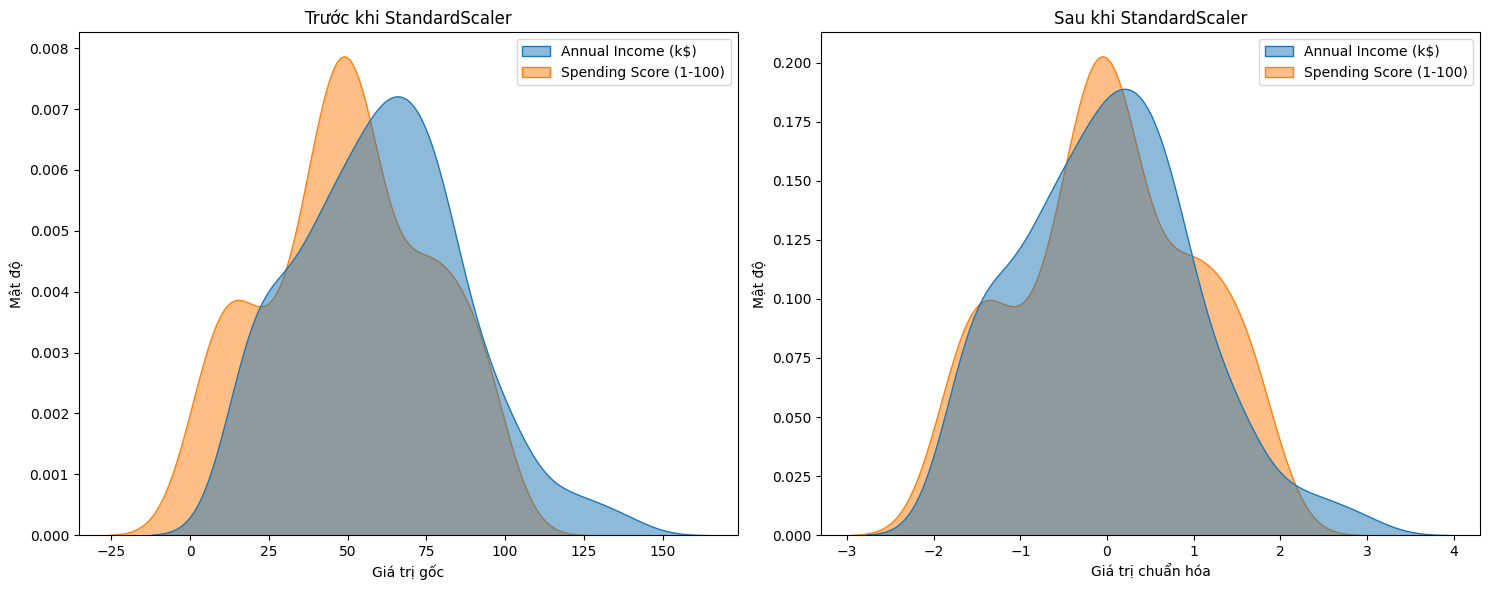

In [28]:
df1 = pd.DataFrame(x, columns=data_before.columns)

# Vẽ biểu đồ so sánh trước và sau khi chuẩn hóa
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Trước khi chuẩn hóa
sns.kdeplot(data=data_before, ax=axes[0], fill=True, alpha=0.5)
axes[0].set_title('Trước khi StandardScaler')
axes[0].set_xlabel('Giá trị gốc')
axes[0].set_ylabel('Mật độ')

# Sau khi chuẩn hóa
sns.kdeplot(data=df1, ax=axes[1], fill=True, alpha=0.5)
axes[1].set_title('Sau khi StandardScaler')
axes[1].set_xlabel('Giá trị chuẩn hóa')
axes[1].set_ylabel('Mật độ')

plt.tight_layout()
plt.show()

giá trị đang bị chênh lệch do mức lương thu nhập có thể vượt quá 140 trong khi điểm tối đa chỉ là 100.vì vậy ta đưa về thang đo chung có độ lệch chuẩn bằng 1 giúp cải thiện performance

2.2 train model KMeans

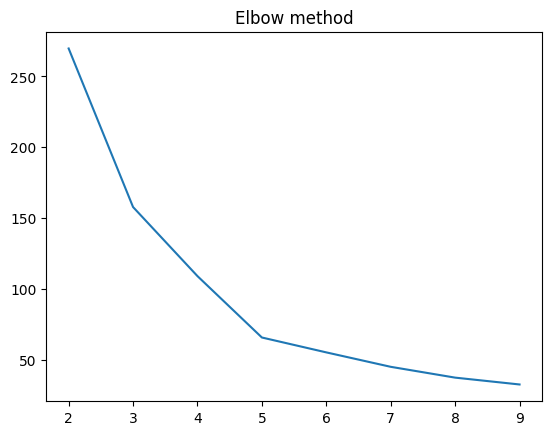

In [30]:
inertia = []
for k in range(2,10):
  model = KMeans(n_clusters=k, n_init = 10 ,random_state=42)
  model.fit(x)
  inertia.append(model.inertia_)
plt.plot(range(2,10), inertia)
plt.title('Elbow method')
plt.show()

ta thấy kể từ k = 5 và k = 3, model bắt đầu có khúc gập và giảm mạnh

In [39]:
# so sánh k tại 3 và 5
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []
for k in [3,5]:
  model = KMeans(init="k-means++", n_clusters=k, random_state=42)
  model.fit(x)
  labels = model.labels_
  silhouette_avg = silhouette_score(x, labels)
  davies_bouldin = davies_bouldin_score(x, labels)
  calinski_harabasz = calinski_harabasz_score(x, labels)
  silhouette_scores.append(silhouette_avg)
  davies_bouldin_scores.append(davies_bouldin)
  calinski_harabasz_scores.append(calinski_harabasz)

table1 = pd.DataFrame({
    'K': [3,5],
    'Silhouette Score': silhouette_scores,
    'Davies-Bouldin Score': davies_bouldin_scores,
    'Calinski-Harabasz Score': calinski_harabasz_scores
})

sill càng tiến gần đến 1 càng tốt

davies càng thấp càng tốt

calinski càng cao càng tốt

In [40]:
table1

,K,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,3,0.466585,0.716482,151.335121
1,5,0.554657,0.572236,248.649320


qua bảng trên cho thấy tại 2 khúc gập 3, 5 . khúc gập 5 cho thấy độ nhỉnh hơn trong việc phân loại cụm dựa vào 3 chỉ số sill, davies, calin

In [41]:
# Chọn k = 5
kmeans = KMeans(
    n_clusters=5,
    init='k-means++',
    n_init=10,
    random_state=42)
kmeans.fit(x)
labels = kmeans.predict(x)
df['Cluster'] = labels

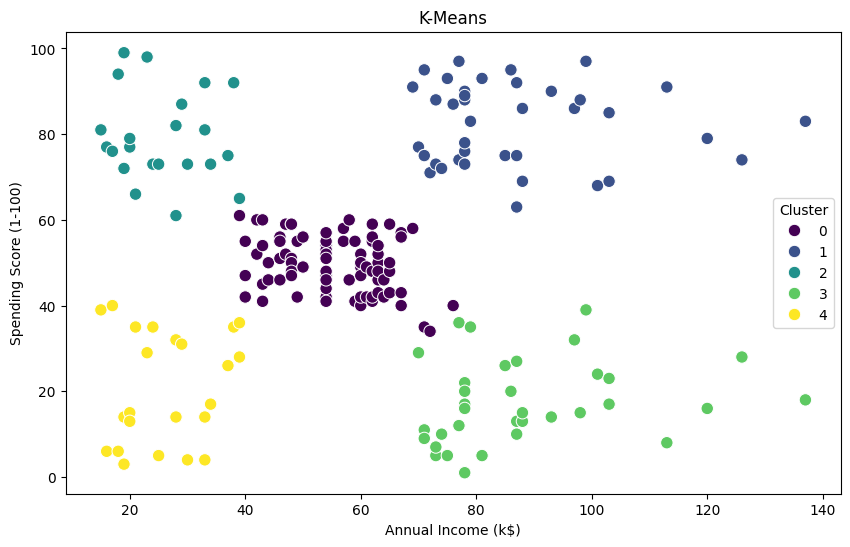

In [43]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,
                x='Annual Income (k$)',
                y='Spending Score (1-100)',
                hue='Cluster',
                palette='viridis',
                s=80)
plt.title('K-Means')
plt.show()

phân tích khách hàng

In [45]:
cluster_analysis = df.groupby('Cluster').agg({
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean',
    'CustomerID': 'count'
}).round(2)
cluster_analysis.rename(columns={
    'CustomerID': 'Number of Customers'
}, inplace=True)

In [46]:
cluster_analysis

,Annual Income (k$),Spending Score (1-100),Number of Customers
Cluster,,,
0,55.30,49.52,81
1,86.54,82.13,39
2,25.73,79.36,22
3,88.20,17.11,35
4,26.30,20.91,23


qua bảng trên ta thấy được 5 loại phân khúc khách hàng
1. loại 0 là khách hàng tầm trung kiếm được vừa và tiêu vừa
2. loại 1 là khách hàng hạng sang kiếm nhiều và tiêu nhiều
3. loại 2 là khách hàng hạng kiếm ít nhưng tiêu nhiều
4. loại 3 là khách hàng loại kiếm nhiều nhưng tiêu ít
5. loại 4 là khách hàng kiếm ít và tiêu ít

2.3 train model DBSCAN

In [48]:
model = DBSCAN(eps=0.3, min_samples=5)
labels = model.fit_predict(x)
df["DBSCAN"] = labels

# đếm số lượng cụm
unique_labels = np.unique(labels)
print("Clusters:", unique_labels)
print("Number of clusters:", len(unique_labels[unique_labels != -1]))
print("Number of noise points:", np.sum(labels == -1))

Clusters: [-1  0  1  2  3  4  5  6]
Number of clusters: 7
Number of noise points: 35


thử điều chỉnh tham số của DBSCAN để tìm tham số thích hợp để chia cụm

In [49]:
model = DBSCAN(eps=0.5, min_samples=5)
labels = model.fit_predict(x)
print("Clusters:", unique_labels)
print("Number of clusters:", len(unique_labels[unique_labels != -1]))
print("Number of noise points:", np.sum(labels == -1))

Clusters: [-1  0  1  2  3  4  5  6]
Number of clusters: 7
Number of noise points: 8


khi tăng bán kính lên thì những điểm đã từng bị coi là noise đã giảm đi đáng kể

dùng phương pháp khuỷu tay để tìm eps thích hợp

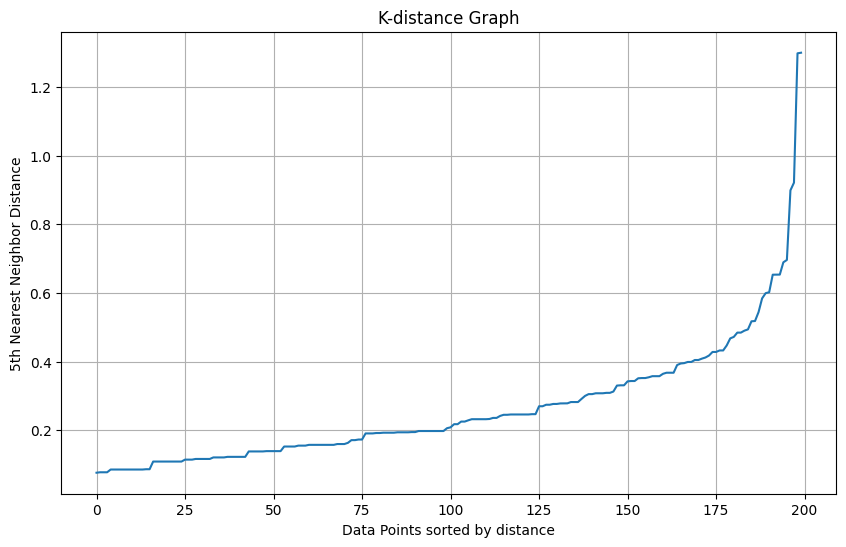

In [52]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(x)
distances, indices = neighbors_fit.kneighbors(x)
distances = np.sort(distances[:, -1])
plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.title('K-distance Graph')
plt.xlabel('Data Points sorted by distance')
plt.ylabel('5th Nearest Neighbor Distance')
plt.grid()
plt.show()

ta thấy được trong khoảng từ 0.4 -> 0.55 model cong rất nhanh nên ta sẽ thử các giá trị trong khoảng này

In [54]:
eps_values = [0.4, 0.45, 0.5, 0.55]

for eps in eps_values:
    dbscan = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = dbscan.fit_predict(x)

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    print(f"eps: {eps}")
    print(f"Clusters: {n_clusters}")
    print(f"Noise points: {n_noise}")
    print("----------------")

eps: 0.4
Clusters: 4
Noise points: 15
----------------
eps: 0.45
Clusters: 3
Noise points: 11
----------------
eps: 0.5
Clusters: 2
Noise points: 8
----------------
eps: 0.55
Clusters: 1
Noise points: 7
----------------


đánh giá các điểm

In [58]:
eps_values = [0.4, 0.45, 0.5]
sill = []
davies = []
calin = []
for eps in eps_values:
    model = DBSCAN(eps=eps,min_samples=5)
    labels = model.fit_predict(x)
    mask = labels != -1
    X_valid = x[mask]
    labels_valid = labels[mask]
    silhouette_avg = silhouette_score(X_valid, labels_valid)
    davies_bouldin = davies_bouldin_score(X_valid, labels_valid)
    calinski_harabasz = calinski_harabasz_score(X_valid, labels_valid)
    sill.append(silhouette_avg)
    davies.append(davies_bouldin)
    calin.append(calinski_harabasz)
table2 = pd.DataFrame({
    'eps': eps_values,
    'Silhouette Score': sill,
    'Davies-Bouldin Score': davies,
    'Calinski-Harabasz Score': calin
})

In [59]:
table2

,eps,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,0.40,0.478059,0.591153,146.887956
1,0.45,0.353641,0.736056,69.062752
2,0.50,0.387558,0.788864,85.389706


ta thấy eps = 0.4 có 3 chỉ số vượt trội hơn 2 cái còn lại nên ta chọn 0.4

In [61]:
dbscan = DBSCAN(eps=0.4,
                min_samples=5)
labels = dbscan.fit_predict(x)
df['DBSCAN_Cluster'] = labels

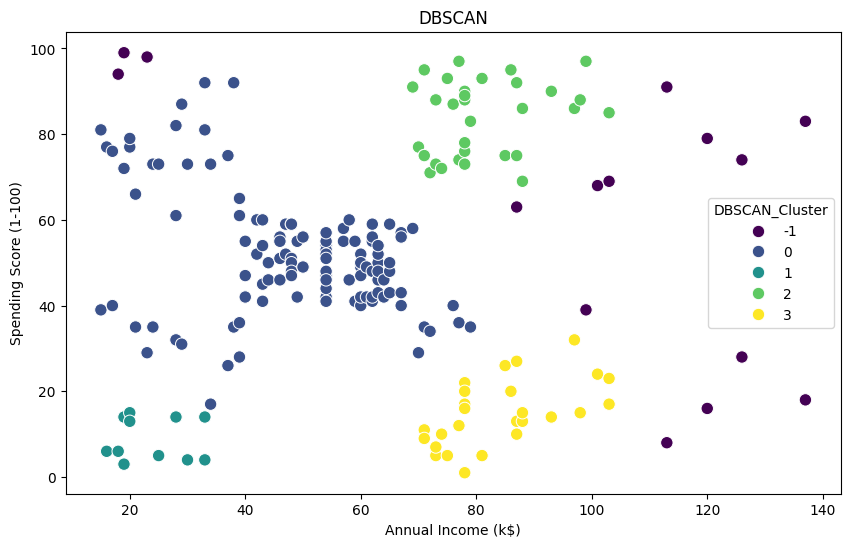

In [64]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='DBSCAN_Cluster',
    palette='viridis',
    s=80
)
plt.title('DBSCAN')
plt.show()

ta thấy DBSCAN chia dữ liệu khách hàng qua mật độ nên chỉ chia thành 4 nhóm có mật độ cao chính và còn lại là noise data

2.4 OPTICS

In [66]:
optics = OPTICS(
    min_samples=5,
    max_eps=np.inf,
    metric='minkowski',
    cluster_method='xi',
    xi=0.05,
    min_cluster_size=0.05)
optics.fit(x)

OPTICS(min_cluster_size=0.05)

In [69]:
labels = optics.labels_
df['OPTICS_Cluster'] = labels
unique_labels = np.unique(labels)
n_clusters = len(set(labels) - {-1})
n_noise = np.sum(labels == -1)
print("Clusters:", unique_labels)
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

Clusters: [-1  0  1  2  3  4  5  6  7]
Number of clusters: 8
Number of noise points: 96


thử tuning để tìm ra tham số chuẩn hơn

In [70]:
min_samples_values = [5, 10, 15]
xi_values = [0.03, 0.05, 0.1]

results = []

for min_samples in min_samples_values:
    for xi in xi_values:
        model = OPTICS(
            min_samples=min_samples,
            xi=xi,
            cluster_method='xi',
            min_cluster_size=0.05)
        labels = model.fit_predict(x)
        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)
        results.append({
            'Min Samples': min_samples,
            'Xi': xi,
            'Clusters': n_clusters,
            'Noise Points': n_noise})
optics_results = pd.DataFrame(results)
print(optics_results)

   Min Samples    Xi  Clusters  Noise Points
0            5  0.03         8            96
1            5  0.05         8            96
2            5  0.10         7           109
3           10  0.03         6            92
4           10  0.05         6            94
5           10  0.10         3            94
6           15  0.03         4            93
7           15  0.05         4            98
8           15  0.10         2           104


In [77]:
results = []

for min_samples in [5,10,15]:
  for xi in [0.03,0.05,0.1]:
    model = OPTICS(min_samples=min_samples, xi=xi, cluster_method='xi', min_cluster_size=0.05)
    labels = model.fit_predict(x)
    mask = labels != -1
    X_valid = x[mask]
    labels_valid = labels[mask]
    n_clusters = len(np.unique(labels_valid))
    n_noise = np.sum(labels == -1)
    if n_clusters >= 2:
      silhouette = silhouette_score(X_valid, labels_valid)
      davies = davies_bouldin_score(X_valid, labels_valid)
      calinski = calinski_harabasz_score(X_valid, labels_valid)
    else:
      silhouette, davies, calinski = np.nan, np.nan, np.nan
    results.append({
        'Min Samples': min_samples,
        'Xi': xi,
        'Clusters': n_clusters,
        'Noise Points': n_noise,
        'Silhouette Score': silhouette,
        'Davies-Bouldin Score': davies,
        'Calinski-Harabasz Score': calinski})
table3 = pd.DataFrame(results)

In [78]:
table3

,Min Samples,Xi,Clusters,Noise Points,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,5,0.03,8,96,0.609322,0.543268,486.869493
1,5,0.05,8,96,0.609322,0.543268,486.869493
2,5,0.10,7,109,0.684362,0.407966,516.944038
3,10,0.03,6,92,0.617385,0.462831,386.314017
4,10,0.05,6,94,0.617064,0.459856,379.156438
5,10,0.10,3,94,0.620003,0.416732,168.161967
6,15,0.03,4,93,0.557607,0.581060,310.222798
7,15,0.05,4,98,0.553282,0.576571,278.907623
8,15,0.10,2,104,0.670287,0.453601,168.832525


xét theo 3 tiếu chí điểm, ta có cấu hình min_samples=5, xi=0.1 là tốt nhất

In [79]:
optics = OPTICS(min_samples=5, xi=0.1, cluster_method='xi', min_cluster_size=0.05)
labels = optics.fit_predict(x)
df['OPTICS_Cluster'] = labels

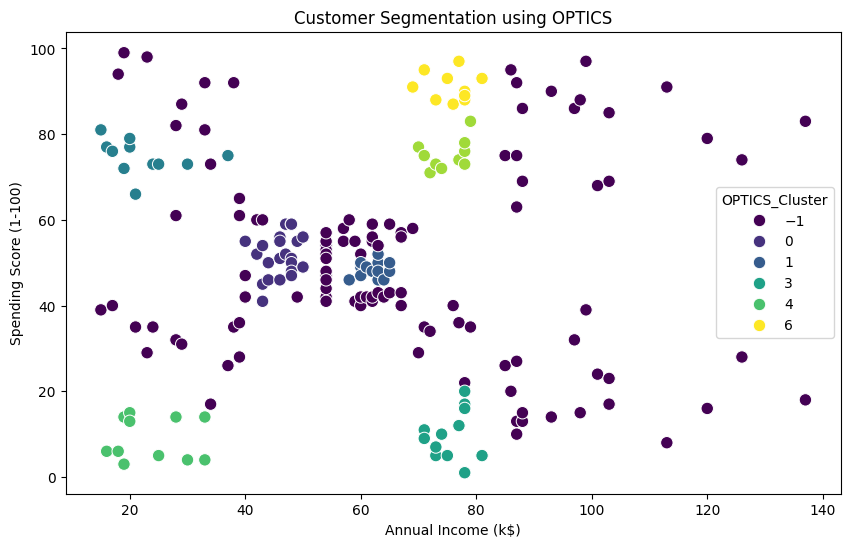

In [80]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='OPTICS_Cluster', palette='viridis', s=80)
plt.title('Customer Segmentation using OPTICS')
plt.show()

Cả ba thuật toán K-Means, DBSCAN và OPTICS đều được sử dụng để phân cụm dữ liệu không có nhãn, nhưng có cách tiếp cận khác nhau:
- K-Means: Phân cụm dựa trên tâm cụm, tốc độ nhanh, dễ triển khai nhưng phải xác định trước số lượng cụm và nhạy cảm với outliers.
- DBSCAN: Phân cụm dựa trên mật độ, không cần xác định số cụm, có khả năng phát hiện noise nhưng nhạy cảm với tham số eps.
- OPTICS: Phát triển từ ý tưởng DBSCAN, có khả năng xử lý các cụm có mật độ khác nhau tốt hơn, nhưng phức tạp và khó lựa chọn tham số hơn.